<h1 style="text-align: center;">Differentiable Coding and Python based MCRT </h1>


In [5]:
import numpy as np
import pandas as pd
import os
import scene
import mcrt
import warnings
import matplotlib.pyplot as plt

In [2]:
choice = "Mie"
delta_m = True
print(os.getcwd())
od_profiles = pd.read_csv("/home/shaizucker/Projects/RTPINN/Data/profile_files/feng_profile.csv")
od_profiles.aer_2 = 0.2 * od_profiles.aer_1
od_profiles.aer_1 = 0.8 * od_profiles.aer_1

n_aer = od_profiles.shape[1] - 2
n_theta = 2001

theta = np.linspace(0, np.pi, n_theta)
cos_theta = np.cos(theta)
# print("test test")
# aerosols related parameters
r_eff = [0.10e-6, 0.10e-6] # in meters
v_eff = [1, 1]
refraction_coef = [[1.3800, 0.1], [1.45, 0]]
wavelength = 0.443e-6
solar_irradiance = 1.0
# Surface related parameters

surface_params = {"rpv_b": -0.5, "rpv_k": 1.5, "rpv_r": 0.17096, "nn": 1.334, "vv": 2.0,
                    "epsirol": 0.0}
surface = scene.Surface("Feng-RPV", surface_params)
# Solar params
mu_0 = np.cos(np.pi * 10.0 / 180.0)
saa = 0.0
solar_irradiance = 1.0
components = []
for i in range(len(od_profiles.columns) - 2):
    components.append(
        scene.MIEAerosol(r_eff[i], v_eff[i], refraction_coef[i], None, None, od_profiles[f"aer_{i + 1}"]))

c_scene = scene.Scene(None, od_profiles.tau.to_numpy(), components, wavelength, mu_0, saa, solar_irradiance, surface, deta=0.0)
solver_inputs = c_scene.gen_optical_params(theta)
mu_view = np.cos(np.arange(0, 91, 1) * np.pi/180)
mu_view[mu_view == 1] = 1 - 1e-10 



/home/shaizucker/Projects/RTPINN/mcrt
not altitude range assuming profile is given


In [3]:
rt_solver = mcrt.MCRT(solver_inputs, theta, 31, 16, mu_view, [0, np.pi], mu_0, 3, 32, 1500, 3)
I_sm_view, Q_sm_view, U_sm_view, mu_0_all, mu_e_all_2 = rt_solver.solve_and_calibrate(n_stokes=3)
dual_mu_view = (180.0 / np.pi) * np.concatenate([-np.arccos(mu_e_all_2).reshape(-1, 1), np.flip(np.arccos(mu_e_all_2).reshape(-1, 1))], axis=0)
I_view = np.concatenate([I_sm_view[1, :], np.flip(I_sm_view[0, :])], axis=0)
Q_view = np.concatenate([Q_sm_view[1, :], np.flip(Q_sm_view[0, :])], axis=0)


1
2
3
4
5
6
7
8
9
10
11
12
13
14
15


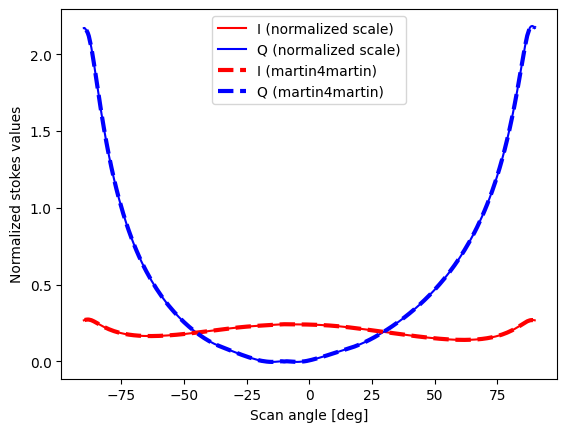

In [4]:
plt.plot(dual_mu_view, I_view, label = "I (normalized scale)",color='r')
plt.plot(dual_mu_view, -10*Q_view, label = "Q (normalized scale)",color='b')
#Load the matlab results and plot them
matlab_I = pd.read_csv(os.path.join("/home/shaizucker/Projects/RTPINN/Data/general/Feng_example", "example_I.csv"), header=None).to_numpy()
plt.plot(matlab_I[:, 0], matlab_I[:, 1], label = "I (martin4martin)", linestyle='--', color='r', linewidth=3)
matlab_Q = pd.read_csv(os.path.join("/home/shaizucker/Projects/RTPINN/Data/general/Feng_example", "example_Q.csv"), header=None).to_numpy()
plt.plot(matlab_Q[:, 0], matlab_Q[:, 1], label = "Q (martin4martin)", linestyle='--', color='b', linewidth=3)
plt.xlabel("Scan angle [deg]")
plt.ylabel("Normalized stokes values")
plt.legend()
plt.show()

# Automatic Differentiation in Physics-based Simulations
# Linear Regression

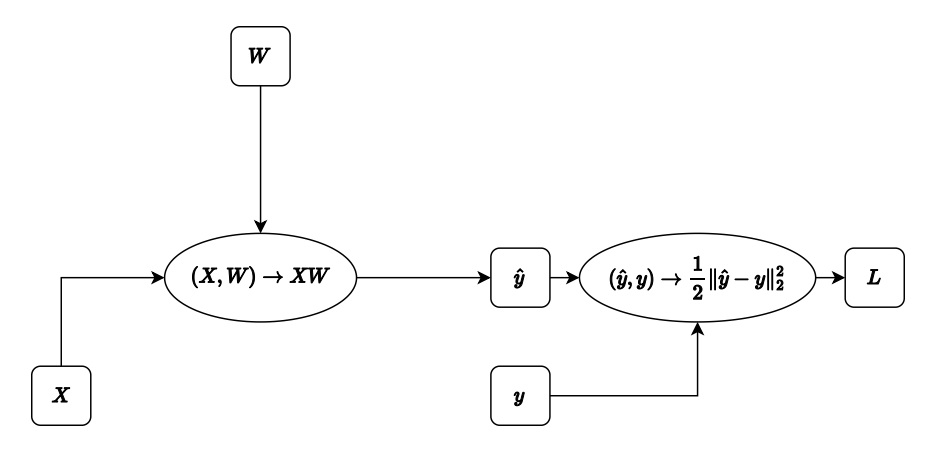

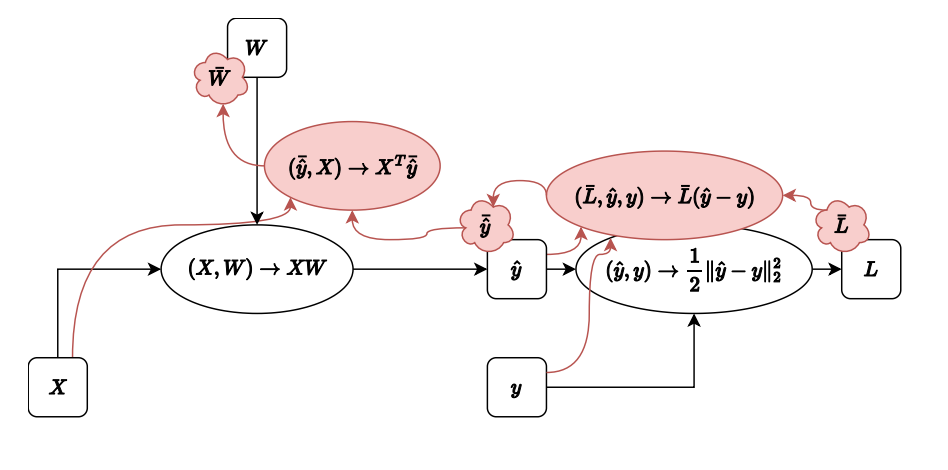
# Scalar Functions

The function is defined as:

$$
y = f(x) = \sin(\exp(x^2)) = l(m(n(x)))
$$

The step-by-step breakdown:

$$
z^{[0]} = x
$$

$$
z^{[1]} = n(z^{[0]}) = (z^{[0]})^2
$$

$$
z^{[2]} = m(z^{[1]}) = \exp(z^{[1]})
$$

$$
z^{[3]} = l(z^{[2]}) = \sin(z^{[2]})
$$

$$
y = z^{[3]}
$$
$$
\frac{\partial y}{\partial x} \;=\;
\frac{\partial y}{\partial z^{[3]}} 
\,\frac{\partial z^{[3]}}{\partial z^{[2]}} 
\,\frac{\partial z^{[2]}}{\partial z^{[1]}} 
\,\frac{\partial z^{[1]}}{\partial z^{[0]}}
\,\frac{\partial z^{[0]}}{\partial x}
$$

## Derivative Computation

The derivative of $y$ with respect to $x$ is given by:

$$
\frac{\partial y}{\partial x} = \frac{\partial y}{\partial z^{[3]}} \frac{\partial z^{[3]}}{\partial z^{[2]}} \frac{\partial z^{[2]}}{\partial z^{[1]}} \frac{\partial z^{[1]}}{\partial z^{[0]}} \frac{\partial z^{[0]}}{\partial x}
$$

### Forward-Mode Differentiation:

$$
\quad \frac{\partial y}{\partial x} = 
\underbrace{\frac{\partial y}{\partial z^{[3]}} \left( \frac{\partial z^{[3]}}{\partial z^{[2]}} \left( \frac{\partial z^{[2]}}{\partial z^{[1]}} \left( \frac{\partial z^{[1]}}{\partial z^{[0]}} \frac{\partial z^{[0]}}{\partial x} \right) \right) \right)}_{\text{forward-mode}}
$$

### Reverse-Mode Differentiation:

$$
\quad \frac{\partial y}{\partial x} = \underbrace{\left( \left( \left( \frac{\partial y}{\partial z^{[3]}} \frac{\partial z^{[3]}}{\partial z^{[2]}} \right) \frac{\partial z^{[2]}}{\partial z^{[1]}} \right) \frac{\partial z^{[1]}}{\partial z^{[0]}} \right) \frac{\partial z^{[0]}}{\partial x}}_{\text{reverse-mode}}
$$

# JAX examples
## jax.jvp
jax.jvp computes the vector product of the function with a given vector
`jax.jvp(fun, primals, tangent)`
The Jacobian is computed as pushforward
The rule of thumb regarding the computation of the gradient states that the Jacobian computation takes less than 2.5 times the primal computation
## jax.vJp
Computes the vector product using reverse mode auto-diff vector-Jacobian product
takes up to 4.0 times as the primal calcuation


$$
\frac{\partial y}{\partial x} \dot{x} = 
\frac{\partial y}{\partial z^{[3]}} \left( \frac{\partial z^{[3]}}{\partial z^{[2]}} \left( \frac{\partial z^{[2]}}{\partial z^{[1]}} \left( \frac{\partial z^{[1]}}{\partial z^{[0]}} \frac{\partial z^{[0]}}{\partial x} \dot{x}\right) \right) \right)
$$

In [5]:
import jax
import jax.numpy as jnp
f = lambda x: jnp.sin(jnp.exp(x**2))
# calculates the partial derivative 
jax.jvp(f, (0.3,), (1.0,))


(Array(0.88854975, dtype=float32, weak_type=True),
 Array(0.3011914, dtype=float32, weak_type=True))

## Vector Auto-Diff
when considering functions defined by scalar operations it is quite straight forward

$$
y = f(x) = [x_0^3\sin(x_1),x_2x_1^2]
$$
$x\in \mathbb{R}^3$ $y\in\mathbb{R}^2 \Rightarrow \frac{\partial y}{\partial x}\in \mathbb{R}^{2\times3}$

In [6]:
f = lambda x: jnp.array([x[0]**3 * jnp.sin(x[1]), x[2]*x[1]**2])
primal = jnp.array([1.0, 2.0, 3.0])
tangent = jnp.array([1.0, 0.0, 0.0])
jax.jvp(f, (primal,), (tangent,))



(Array([ 0.9092974, 12.       ], dtype=float32),
 Array([2.7278922, 0.       ], dtype=float32))

In [7]:
output, vjp_fun = jax.vjp(f, primal)
cotangent = jnp.array([1.0, 0.0])
vjp_fun(cotangent)


(Array([ 2.7278922 , -0.41614684,  0.        ], dtype=float32),)

# Full Jacobian Evaluation

finding the entire Jacobian is more computationally extensive but can be done

$$
f(x) = \sin(A^3 x) + \exp(A^2 x)
$$

where:
-  $A$ is a $ 3 \times 3$ matrix.
- $x$ is a 3D input vector.
- The function applies both sin and exp non-linearly.

The Jacobian is computed using:
$$
J(x) = \cos(A^3 x) A^3 + \exp(A^2 x) A^2
$$
*`jax.jacfwd(f)` computes the Jacobian of `f` using **forward-mode autodiff**, which is efficient when the number of inputs is small.  
*`jax.jacrev(f)` computes the Jacobian of `f` using **reverse-mode autodiff**, which is efficient when the number of outputs is small (useful for deep learning).



In [8]:
A = jnp.array([[2, 0, 1], 
               [0, 3, 0], 
               [0, 0, 1]])

def f(x):
    Ax3 = jnp.linalg.matrix_power(A, 3) @ x  # A^3 * x
    Ax2 = jnp.linalg.matrix_power(A, 2) @ x  # A^2 * x
    return jnp.sin(Ax3) + jnp.exp(Ax2)

jacobian_jax = jax.jacfwd(f)(jnp.array([1.0, 1.0, 1.0]))

x_input = jnp.array([1.0, 1.0, 1.0])
Ax3 = jnp.linalg.matrix_power(A, 3) @ x_input
Ax2 = jnp.linalg.matrix_power(A, 2) @ x_input
analytical_jacobian = jnp.diag(jnp.cos(Ax3)) @ jnp.linalg.matrix_power(A, 3) + \
                      jnp.diag(jnp.exp(Ax2)) @ jnp.linalg.matrix_power(A, 2)

print("JAX computed Jacobian:\n", jacobian_jax)
print("\nAnalytical Jacobian:\n", analytical_jacobian)

JAX computed Jacobian:
 [[4.3804551e+03 0.0000000e+00 3.2845815e+03]
 [0.0000000e+00 7.2919867e+04 0.0000000e+00]
 [0.0000000e+00 0.0000000e+00 3.2585840e+00]]

Analytical Jacobian:
 [[4.3804551e+03 0.0000000e+00 3.2845815e+03]
 [0.0000000e+00 7.2919867e+04 0.0000000e+00]
 [0.0000000e+00 0.0000000e+00 3.2585840e+00]]


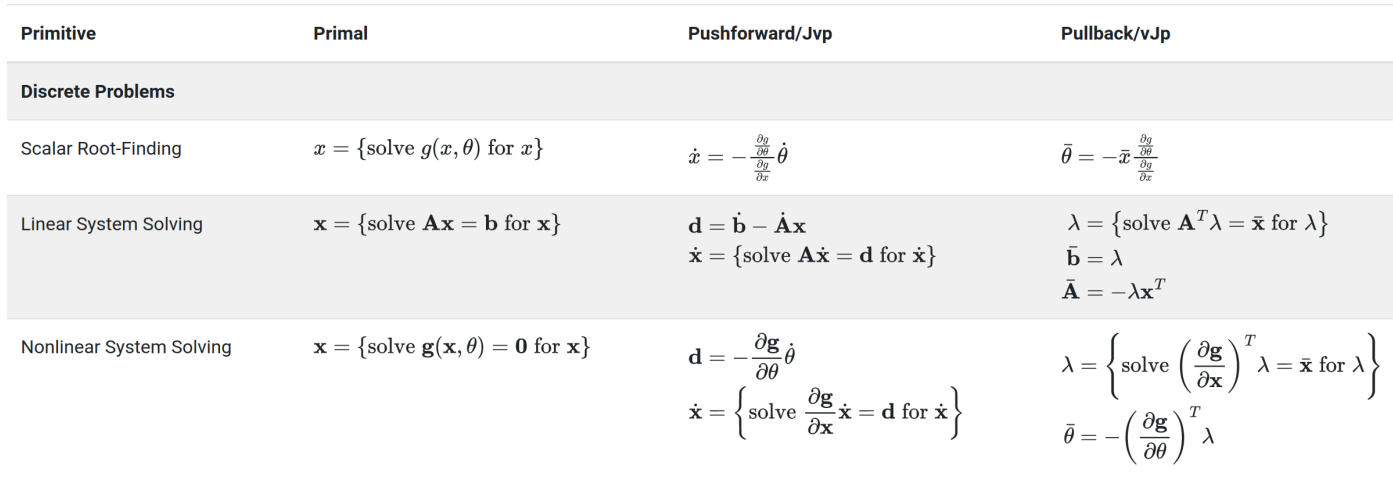

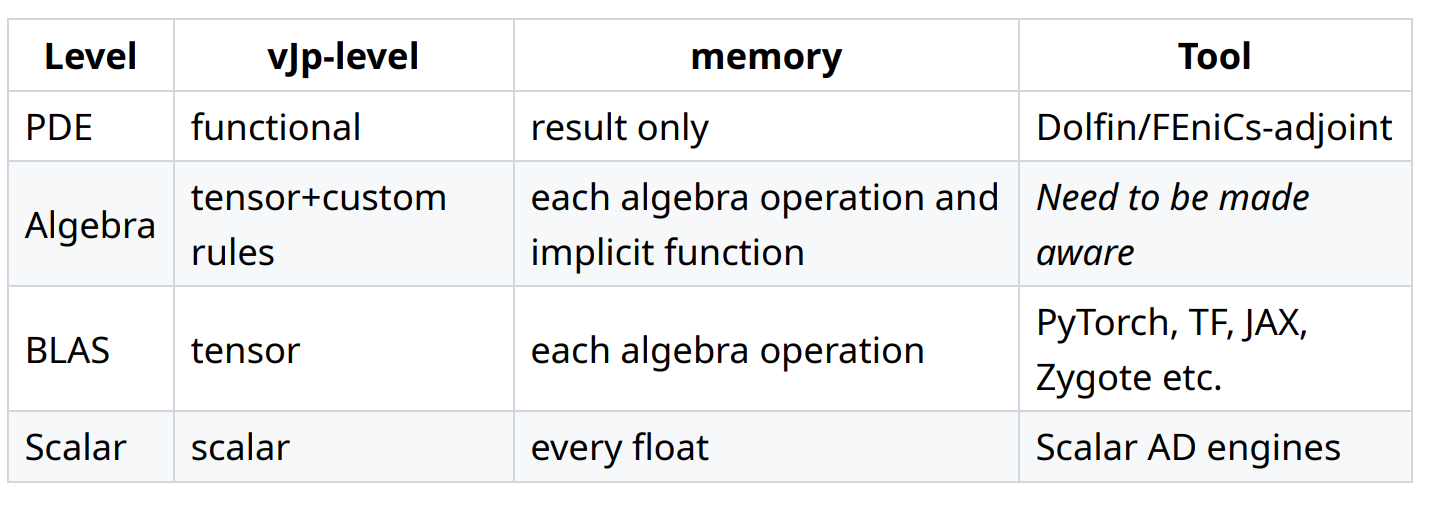